# 13 · Final test (Phase 13) and saved models (Phase 15)

This notebook freezes the three models, saves them to `backend/models/`, and only then opens the test set, once.

| Step | What happens |
|---|---|
| 1 | **Freeze**: take each model exactly as Phase 11/12 left it. No more tuning. |
| 2 | **Save** to `models/`: `softmax.joblib`, `svm.joblib`, `mlp.joblib` and `metrics.json`, *before* the test set is read. |
| 3 | **Open the test set**: 36,000 squares from 900 photos no model has ever seen. |
| 4 | **Score each model once** on the same scorecard as validation. |
| 5 | Read the result. |

**Key idea:** validation picked the settings, so validation scores are a little optimistic. The test set was never used for any choice, so it is the honest estimate of how the models do on new roads.

In [1]:
import hashlib
import json
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
                             precision_recall_fscore_support)
from sklearn.svm import SVC

sys.path.insert(0, str(Path.cwd().parents[1]))
from ml import config, features
from ml.training import LABELS, NAMES, floor_macro_f1, load_data, load_test, make_pipeline, output_dir

SEED = config.SEED
OUT = output_dir("13_test")          # charts and tables from this notebook
MODELS = config.MODELS               # backend/models/: what the app will load
MODELS.mkdir(exist_ok=True)
NONE, D40 = config.CLASS_TO_ID["none"], config.CLASS_TO_ID["D40"]

data = load_data()                   # balanced train + validation, as in Phase 11
print("train", data.X_tr.shape, "| val", data.X_va.shape, "| scikit-learn", sklearn.__version__)

train (46408, 1769) | val (36000, 1769) | scikit-learn 1.7.2


## 1 · Freeze the three models

| Model | Owner | Frozen settings | Status | Validation macro F1 |
|---|---|---|---|---|
| Softmax | Rafat | `C=10`, `class_weight="balanced"`, `max_iter=2000` | first pass | 0.2094 |
| SVM (RBF) | Rotana | `C=10`, `gamma="scale"`, `class_weight="balanced"`, `probability=True` | first pass | 0.2571 |
| MLP | team lead | `(256, 128)`, `alpha=0.0001`, early stopping, balanced sample weights | tuned + Phase 12 | 0.2234 |

All three use the agreed pipeline `StandardScaler → PCA(60) → model`, trained on the 46,408 balanced training squares.

Where each copy comes from, in this order:
1. `models/<name>.joblib` already exists → it is already frozen: load it, never refit.
2. The notebook's `best_pipeline.joblib` is on this machine → copy it.
3. Otherwise → refit with the settings above. Softmax takes seconds. The SVM takes about 80 min, because `probability=True` trains 5 extra models to learn its confidence scores.

**Key idea:** a frozen copy must give its notebook's validation score again. If it does, it is the same model, whichever of the three routes it came from.

In [2]:
FROZEN = {
    "softmax": dict(title="Softmax regression", notebook="11_1_softmax", owner="Rafat", status="first pass",
                    val_macro_f1=0.2094,
                    build=lambda: make_pipeline(LogisticRegression(C=10, class_weight="balanced", max_iter=2000,
                                                                   random_state=SEED))),
    "svm": dict(title="SVM (RBF kernel)", notebook="11_2_svm", owner="Rotana", status="first pass",
                val_macro_f1=0.2571,
                build=lambda: make_pipeline(SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced",
                                                probability=True, random_state=SEED))),
    "mlp": dict(title="MLP neural network", notebook="11_3_mlp", owner="team lead", status="tuned + Phase 12",
                val_macro_f1=0.2234, build=None),   # MLP needs sample weights: only ever copied from 11_3
}


def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


pipes, val_pred, freeze_log = {}, {}, []
for name, spec in FROZEN.items():
    frozen, source = MODELS / f"{name}.joblib", config.PROCESSED / spec["notebook"] / "best_pipeline.joblib"
    t = time.perf_counter()
    if frozen.exists():
        pipe, how = joblib.load(frozen), "already frozen"
    elif source.exists():
        pipe, how = joblib.load(source), f"copied from {spec['notebook']}"
    elif spec["build"] is not None:
        pipe, how = spec["build"]().fit(data.X_tr, data.y_tr), "refit with the frozen settings"
    else:
        raise FileNotFoundError(f"{source} is missing: run step 8 of {spec['notebook']}.ipynb first")
    secs = time.perf_counter() - t

    val_pred[name] = pipe.predict(data.X_va)
    f = f1_score(data.y_va, val_pred[name], labels=LABELS, average="macro", zero_division=0)
    diff = f - spec["val_macro_f1"]
    assert abs(diff) < 0.01, f"{name}: val macro F1 {f:.4f} is not the notebook's {spec['val_macro_f1']}: not the same model"
    if not frozen.exists():
        joblib.dump(pipe, frozen)
    pipes[name] = pipe
    freeze_log.append({"model": name, "source": how, "seconds": round(secs, 1),
                       "val macro F1 now": round(f, 4), "in its notebook": spec["val_macro_f1"],
                       "same": abs(diff) < 0.001, "file MB": round(frozen.stat().st_size / 1e6, 2)})

pd.DataFrame(freeze_log)

,model,source,seconds,val macro F1 now,in its notebook,same,file MB
0,softmax,already frozen,0.0,0.2094,0.2094,True,0.48
1,svm,already frozen,0.0,0.2571,0.2571,True,20.76
2,mlp,already frozen,0.1,0.2234,0.2234,True,1.08


## 2 · Save `metrics.json` next to the models (Phase 15)

`models/` now holds everything the app will ever need from the ML side:

| File | What it is |
|---|---|
| `softmax.joblib`, `svm.joblib`, `mlp.joblib` | the whole fitted pipeline: scaler + PCA + model. Input: 1,769 numbers from `features.extract()`. Output: one of 5 classes, plus probabilities. |
| `metrics.json` | for each model: settings, validation scores, file fingerprint (SHA-256), versions. Test scores are added in step 4. |

**Key idea:** the app reads `models/` and `ml/features.py`, nothing else. It never opens a notebook. That is what makes the notebooks swappable: retrain, overwrite `models/`, restart the app.

The SHA-256 fingerprint is how we tell later whether a `.joblib` file is still the one that was tested.

In [3]:
def val_scores(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=LABELS, zero_division=0)
    clean = y == NONE
    return {"macro_f1": round(float(f1_score(y, pred, labels=LABELS, average="macro", zero_division=0)), 4),
            "accuracy": round(float(accuracy_score(y, pred)), 4),
            "pothole_recall": round(float(r[D40]), 4),
            "clean_road_flagged": round(float((pred[clean] != NONE).mean()), 4),
            "per_class": {c: {"precision": round(float(p[i]), 4), "recall": round(float(r[i]), 4),
                              "f1": round(float(f[i]), 4)} for i, c in enumerate(config.CLASSES)}}


def model_card(name, spec, pipe):
    path = MODELS / f"{name}.joblib"
    clf = pipe.named_steps["clf"]
    keep = {"C", "gamma", "kernel", "class_weight", "max_iter", "hidden_layer_sizes", "alpha", "early_stopping"}
    return {"title": spec["title"], "file": path.name, "sha256": sha256(path),
            "size_mb": round(path.stat().st_size / 1e6, 2),
            "frozen_at": datetime.fromtimestamp(path.stat().st_mtime, timezone.utc).isoformat(timespec="seconds"),
            "trained_in": f"ml/notebooks/{spec['notebook']}.ipynb", "owner": spec["owner"], "status": spec["status"],
            "pipeline": [f"{n}: {type(s).__name__}" for n, s in pipe.steps],
            "settings": {k: (list(v) if isinstance(v, tuple) else v) for k, v in clf.get_params().items() if k in keep},
            "has_predict_proba": hasattr(pipe, "predict_proba"),
            "validation": val_scores(data.y_va, val_pred[name]),
            "test": None}


metrics = {
    "project": "Road Damage Classifier",
    "classes": config.CLASSES,
    "class_names": NAMES,
    "input": {"square_px": config.SQUARE, "features": features.N_FEATURES,
              "feature_code": "ml/features.py extract()", "photo": f"{config.IMG_W} x {config.IMG_H}, 8 x 5 squares"},
    "trained_on": {"squares": int(len(data.y_tr)), "photos": int(len(np.unique(data.groups_tr))), "balanced": True},
    "versions": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__, "numpy": np.__version__,
                 "joblib": joblib.__version__},
    "validation_floor_macro_f1": round(float(floor_macro_f1(data.y_va)), 4),
    "models": {name: model_card(name, spec, pipes[name]) for name, spec in FROZEN.items()},
}
(MODELS / "metrics.json").write_text(json.dumps(metrics, indent=2))
print("models/:", ", ".join(f"{p.name} ({p.stat().st_size / 1e6:.2f} MB)" for p in sorted(MODELS.glob("*.*"))))

models/: .gitkeep (0.00 MB), metrics.json (0.01 MB), mlp.joblib (1.08 MB), softmax.joblib (0.48 MB), svm.joblib (20.76 MB)


## 3 · Open the test set (once)

The test squares come from 900 photos (300 per country) that were split off in Phase 7, before balancing, features or tuning, and never loaded since.

**Re-run guard.** Running this notebook again with the *same* frozen files is harmless: the numbers come out identical. If a `.joblib` file has changed since the last test run (someone retrained), the cell stops, unless you set `RETEST = True` on purpose. See section 6 on when that is fine.

In [4]:
RETEST = False   # True only after a deliberate retrain (section 6)

previous, changed, first_tested_at = OUT / "test_results.json", [], None
if previous.exists():
    old = json.loads(previous.read_text())
    changed = [n for n in FROZEN if old["models"].get(n, {}).get("sha256") != metrics["models"][n]["sha256"]]
    if changed and not RETEST:
        raise RuntimeError(f"{changed} changed since the test run of {old['tested_at']}: "
                           "set RETEST = True only if this retrain is deliberate (section 6)")
    first_tested_at = None if changed else old["tested_at"]   # same files: keep the date of the first look
    print(f"test already scored on {old['tested_at']};",
          "same frozen models, so the same numbers" if not changed else f"RETEST of {changed}")

test = load_test()
seen = set(data.groups_tr) & set(test.image_id)
assert not seen, f"{len(seen)} test photos are also training photos"

counts = pd.crosstab(pd.Series(test.country, name="country"),
                     pd.Series([config.CLASSES[i] for i in test.y], name="class"), margins=True, margins_name="total")
print(f"test: {len(test.y):,} squares from {len(np.unique(test.image_id))} photos | no overlap with training photos")
counts

test already scored on 2026-11-24T03:28:14+00:00; same frozen models, so the same numbers


test: 36,000 squares from 900 photos | no overlap with training photos


class,D00,D10,D20,D40,none,total
country,,,,,,
Czech,258,104,109,30,13019,13520
India,179,8,640,246,9687,10760
Japan,353,241,1720,84,9322,11720
total,790,353,2469,360,32028,36000


## 4 · Score each model once

The same scorecard as validation:

| Measure | Meaning | Good is |
|---|---|---|
| **macro F1** | average of the 5 per-class F1 scores, so every class counts the same, however rare | higher; the floor (always "none") is about 0.19 |
| **pothole recall** | of the real potholes (D40), the share the model found | higher |
| **clean road flagged** | of the clean squares ("none"), the share wrongly called damage (false alarms) | lower |

In [5]:
test_pred, rows = {}, []
for name, pipe in pipes.items():
    t = time.perf_counter()
    test_pred[name] = pipe.predict(test.X)
    secs = time.perf_counter() - t
    s = val_scores(test.y, test_pred[name])
    s["confusion_matrix"] = confusion_matrix(test.y, test_pred[name], labels=LABELS).tolist()
    s["predict_ms_per_photo"] = round(secs / len(test.y) * 40 * 1000, 2)   # 40 squares per photo
    metrics["models"][name]["test"] = s
    v = metrics["models"][name]["validation"]
    rows.append({"model": name, "val macro F1": v["macro_f1"], "test macro F1": s["macro_f1"],
                 "change": round(s["macro_f1"] - v["macro_f1"], 4),
                 "val pothole recall": v["pothole_recall"], "test pothole recall": s["pothole_recall"],
                 "val clean flagged": v["clean_road_flagged"], "test clean flagged": s["clean_road_flagged"],
                 "test accuracy": s["accuracy"], "ms per photo": s["predict_ms_per_photo"]})

floor = round(float(floor_macro_f1(test.y)), 4)
metrics["test_floor_macro_f1"] = floor
summary = pd.DataFrame(rows).set_index("model")
summary.to_csv(OUT / "test_summary.csv")
print(f"test floor (always 'none'): macro F1 {floor}")
summary

test floor (always 'none'): macro F1 0.1883


,val macro F1,test macro F1,change,val pothole recall,test pothole recall,val clean flagged,test clean flagged,test accuracy,ms per photo
model,,,,,,,,,
softmax,0.2094,0.2164,0.0070,0.5085,0.4361,0.4802,0.4660,0.5076,0.26
svm,0.2571,0.2528,-0.0043,0.2591,0.2306,0.3795,0.3659,0.6095,77.68
mlp,0.2234,0.2240,0.0006,0.6102,0.5361,0.4643,0.4499,0.5227,0.48


,softmax,svm,mlp
D00 · Longitudinal crack,0.078,0.098,0.091
D10 · Transverse crack,0.059,0.069,0.064
D20 · Alligator crack,0.204,0.250,0.204
D40 · Pothole,0.051,0.080,0.058
none · No damage,0.690,0.767,0.703


,softmax,svm,mlp
D00 · Longitudinal crack,0.220,0.276,0.301
D10 · Transverse crack,0.422,0.252,0.323
D20 · Alligator crack,0.280,0.503,0.264
D40 · Pothole,0.436,0.231,0.536
none · No damage,0.534,0.634,0.550


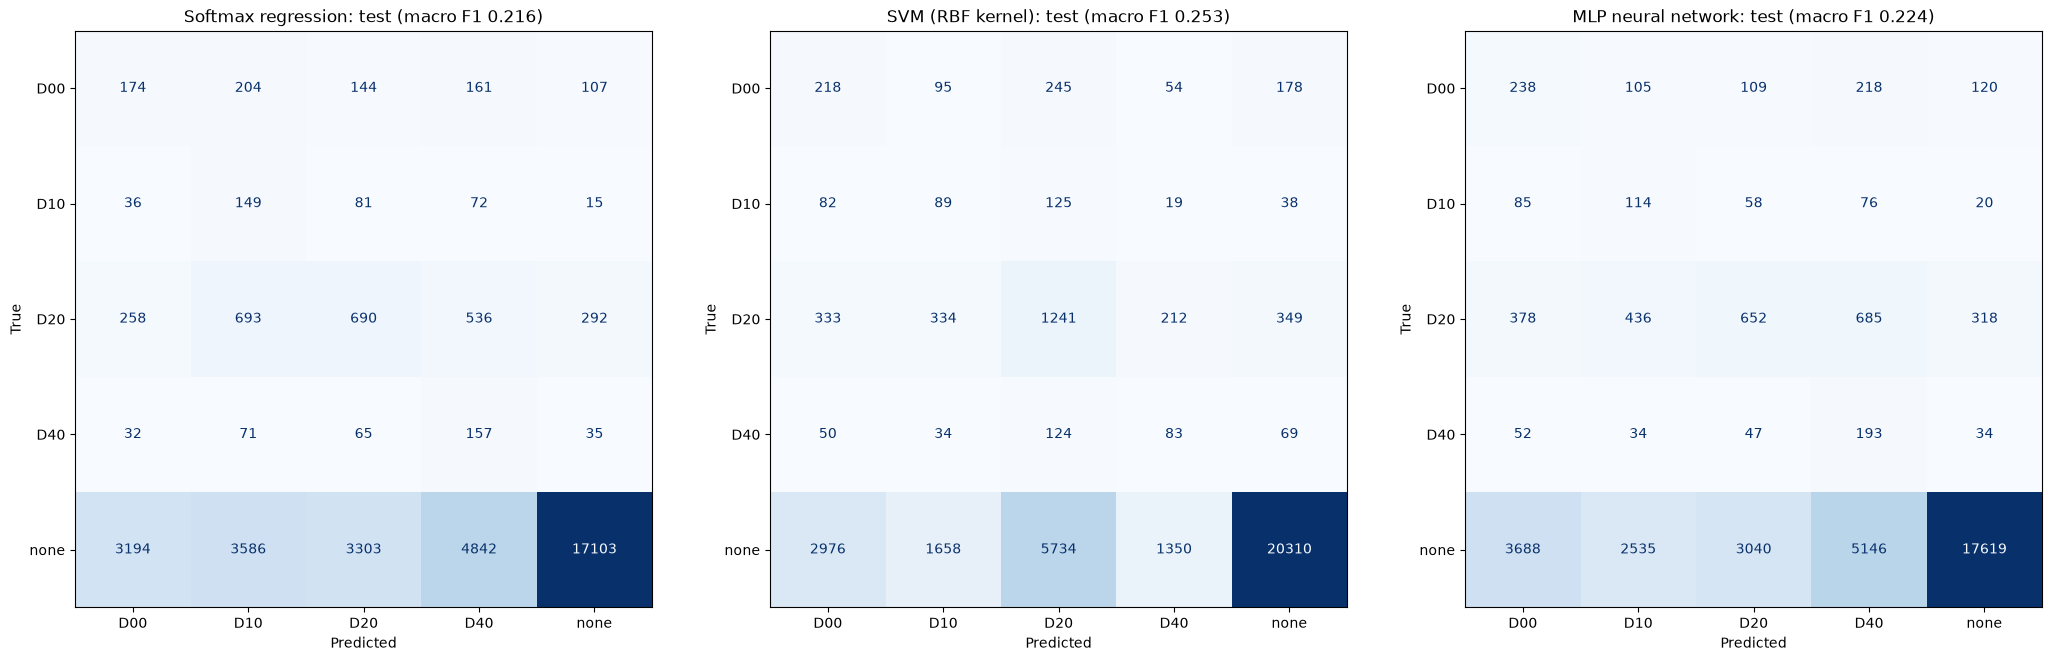

In [6]:
per_class = pd.DataFrame({n: {c: metrics["models"][n]["test"]["per_class"][c]["f1"] for c in config.CLASSES}
                          for n in pipes}).rename(index=dict(zip(config.CLASSES, NAMES)))
recall = pd.DataFrame({n: {c: metrics["models"][n]["test"]["per_class"][c]["recall"] for c in config.CLASSES}
                       for n in pipes}).rename(index=dict(zip(config.CLASSES, NAMES)))
display(per_class.style.format("{:.3f}").set_caption("test F1 per class"))
display(recall.style.format("{:.3f}").set_caption("test recall per class"))

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, (name, pipe) in zip(axes, pipes.items()):
    cm = np.array(metrics["models"][name]["test"]["confusion_matrix"])
    ConfusionMatrixDisplay(cm, display_labels=[c for c in config.CLASSES]).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set(title=f"{FROZEN[name]['title']}: test (macro F1 {metrics['models'][name]['test']['macro_f1']:.3f})",
           xlabel="Predicted", ylabel="True")
fig.tight_layout()
fig.savefig(OUT / "test_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

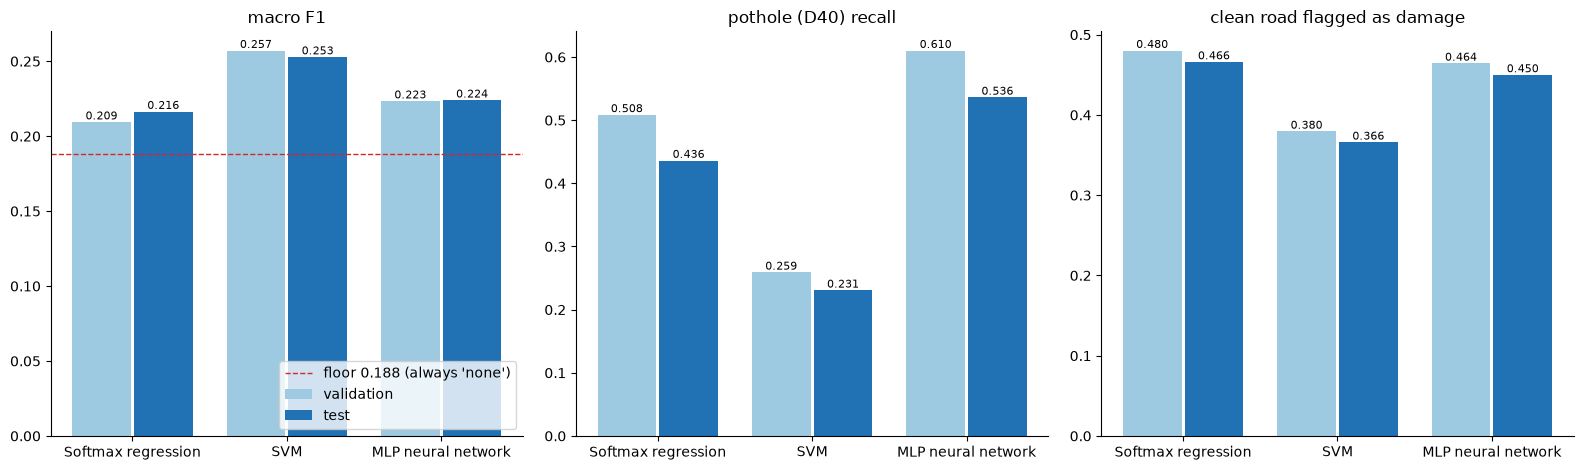

In [7]:
# Validation vs test, the three numbers the slides use
panels = [("macro F1", "macro_f1", floor), ("pothole (D40) recall", "pothole_recall", None),
          ("clean road flagged as damage", "clean_road_flagged", None)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
x = np.arange(len(pipes))
for ax, (title, key, line) in zip(axes, panels):
    v = [metrics["models"][n]["validation"][key] for n in pipes]
    t = [metrics["models"][n]["test"][key] for n in pipes]
    b1 = ax.bar(x - 0.2, v, 0.38, label="validation", color="#9ecae1")
    b2 = ax.bar(x + 0.2, t, 0.38, label="test", color="#2171b5")
    ax.bar_label(b1, fmt="%.3f", fontsize=8); ax.bar_label(b2, fmt="%.3f", fontsize=8)
    if line:
        ax.axhline(line, ls="--", color="#d62728", lw=1, label=f"floor {line:.3f} (always 'none')")
    ax.set_xticks(x, [FROZEN[n]["title"].split(" (")[0] for n in pipes])
    ax.set_title(title); ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUT / "val_vs_test.png", dpi=150, bbox_inches="tight")
plt.show()

### Per country

The test photos are 300 per country. A model that only works on one country's roads would show it here.

In [8]:
rows = []
for name in pipes:
    for c in config.COUNTRIES:
        m = test.country == c
        s = val_scores(test.y[m], test_pred[name][m])
        rows.append({"model": name, "country": c, "macro F1": s["macro_f1"], "pothole recall": s["pothole_recall"],
                     "clean flagged": s["clean_road_flagged"], "potholes": int((test.y[m] == D40).sum())})
by_country = pd.DataFrame(rows)
by_country.to_csv(OUT / "test_by_country.csv", index=False)
for name in pipes:
    metrics["models"][name]["test"]["by_country"] = {
        r["country"]: {"macro_f1": r["macro F1"], "pothole_recall": r["pothole recall"],
                       "clean_road_flagged": r["clean flagged"]} for r in rows if r["model"] == name}
by_country.pivot(index="country", columns="model", values=["macro F1", "pothole recall", "clean flagged"]).round(3)

macro F1                pothole recall                clean flagged  \
model        mlp softmax    svm            mlp softmax    svm           mlp   
country                                                                       
Czech      0.200   0.188  0.227          0.200   0.133  0.033         0.342   
India      0.184   0.172  0.218          0.699   0.598  0.309         0.495   
Japan      0.215   0.215  0.240          0.179   0.071  0.071         0.553   

                        
model   softmax    svm  
country                 
Czech     0.361  0.245  
India     0.533  0.409  
Japan     0.543  0.490

### Save the test results

`metrics.json` in `models/` gets the test scores; `13_test/test_results.json` records which files (by SHA-256) were tested and when, for the re-run guard.

In [9]:
tested_at = first_tested_at or datetime.now(timezone.utc).isoformat(timespec="seconds")
metrics["tested_at"] = tested_at
(MODELS / "metrics.json").write_text(json.dumps(metrics, indent=2))
(OUT / "test_results.json").write_text(json.dumps(
    {"tested_at": tested_at, "test_squares": int(len(test.y)), "floor_macro_f1": floor,
     "models": {n: {"sha256": metrics["models"][n]["sha256"], **{k: metrics["models"][n]["test"][k]
               for k in ("macro_f1", "accuracy", "pothole_recall", "clean_road_flagged")}} for n in pipes}},
    indent=2))
print("saved:", ", ".join(sorted(p.name for p in OUT.iterdir())))

saved: test_by_country.csv, test_confusion_matrices.png, test_results.json, test_summary.csv, val_vs_test.png


### What the app will do with one photo (preview, not the app)

Each photo becomes 40 squares; each square gets a class and a confidence from `predict_proba`. Here the 40 squares of one test photo are already turned into numbers. The app will compute those numbers from the uploaded photo with the same `features.extract()`.

Models are reloaded from `models/` to show that the saved files are all you need.

In [10]:
app_model = joblib.load(MODELS / "mlp.joblib")   # loaded fresh from disk, as the app will
photo = test.image_id[np.flatnonzero(test.y == D40)[0]]   # a test photo with a pothole
rows40 = np.flatnonzero(test.image_id == photo)
proba = app_model.predict_proba(test.X[rows40])
grid_pred = np.array(config.CLASSES)[proba.argmax(1)].reshape(5, 8)
grid_true = np.array(config.CLASSES)[test.y[rows40]].reshape(5, 8)
conf = proba.max(1).reshape(5, 8)

print(f"photo {photo}: predicted class and confidence per square (5 rows x 8 columns, top = far away)")
print("* = wrong; true classes below\n")
for r in range(5):
    print("  ".join(f"{grid_pred[r, c]:>4s} {conf[r, c]:.2f}{'*' if grid_pred[r, c] != grid_true[r, c] else ' '}"
                    for c in range(8)))
print()
for r in range(5):
    print("  ".join(f"{grid_true[r, c]:>4s}      " for c in range(8)))

photo Czech_000064: predicted class and confidence per square (5 rows x 8 columns, top = far away)
* = wrong; true classes below

none 0.75   none 0.99   none 0.99   none 1.00   none 0.99   none 0.92   none 0.95   none 0.95 
none 0.82   none 0.94   none 0.86   none 0.96   none 1.00   none 0.99   none 0.85   none 1.00 
 D00 0.40*   D00 0.54*   D40 0.50*   D40 0.34*   D00 0.38*  none 0.39    D10 0.61*  none 0.73 
 D00 0.44*   D00 0.63*   D00 0.53*   D00 0.56*   D00 0.38*   D00 0.32*   D00 0.32*   D20 0.33*
none 0.89   none 0.95   none 0.98   none 0.92   none 0.85   none 0.74   none 0.83   none 0.49 

none        none        none        none        none        none        none        none      
none        none        none        none        none        none        none        none      
none         D40        none        none        none        none        none        none      
none        none        none        none        none        none        none        none      
none        no

## 5 · What the test says

| Model | Val macro F1 | **Test macro F1** | Test pothole recall | Test clean road flagged | Speed per photo | File |
|---|---|---|---|---|---|---|
| Softmax | 0.209 | **0.216** | 0.44 | 47% | 0.3 ms | 0.5 MB |
| SVM | 0.257 | **0.253** | 0.23 | 37% | 83 ms | 21 MB |
| MLP | 0.223 | **0.224** | 0.54 | 45% | 0.3 ms | 1.1 MB |

Floor (always "none") on test: 0.188.

1. **Test ≈ validation.** Every model moved by less than 0.01 macro F1 (softmax +0.007, SVM −0.004, MLP +0.001).
   *What it means:* tuning on validation did not fool us; the validation numbers on the slides were honest.
2. **The ranking holds.** SVM is best on the main metric (macro F1), MLP is the best pothole finder, softmax is the reference.
3. **Better than guessing, far from useful on its own.** All three beat the floor, but only by 0.03–0.07. Damage-class F1 stays between 0.05 and 0.25 because precision is tiny: for D40, 3–5% of "pothole" answers are real potholes. About 4 in 10 clean squares are flagged as damage.
4. **Potholes depend on the country.** Pothole recall dropped from val to test (MLP 0.61 → 0.54). Per country, the MLP finds 70% of India's potholes but only 18–20% of Japan's and Czech's, where potholes are rare (84 and 30 in test).
5. **Speed is fine for the app.** One photo (40 squares) takes 0.3 ms with softmax or MLP and 83 ms with the SVM, which compares each square with its 37,004 support vectors. All three are fast enough for one uploaded photo at a time.

**Key idea:** the features (HOG + 5 measures on 80 px squares) are the ceiling, as Phase 12 showed: three very different models land within 0.04 of each other. These are the frozen Phase 13 numbers for the report.

## 6 · Can we retrain later?

Yes. Freezing is about **knowing which model a number belongs to**, not about never training again.

1. **Tweak on validation, never on test.** Any new idea (new features, half-strength weights, a different threshold) is tried in its Phase 11/12 notebook and judged on validation, as before.
2. **Freeze the new version.** Delete (or move) the old `models/<name>.joblib`, run section 1 again: it copies the new `best_pipeline.joblib`.
3. **Test it once.** Set `RETEST = True`. The guard exists so a retest is a decision, not an accident.
4. **Report it honestly.** The second test score is slightly less "unseen" than the first, because we already know what the test set punished. Report both runs, not just the better one.